# Lab 3 — Deep Learning Notebook Walkthrough  
**Topic:** Training & validation curves + simple fixes (learning rate, dropout, epochs)

## What you will do (in class)
1. Run the baseline model end-to-end  
2. Plot **training vs validation** curves  
3. Change **ONE** thing (choose: learning rate **or** dropout **or** epochs)  
4. Compare baseline vs changed version (take **1 screenshot**)  
5. Write a **6-sentence memo** (template at the end)

> **Dataset:** Fashion-MNIST (10 classes of clothing images)  
> **Goal:** Predict the correct class for each image (classification)

---
### Quick concept notes (simple words)
- **Training** = the model learns patterns from examples.
- **Validation** = a “practice test” during training. Helps us see if we are overfitting.
- **Overfitting** = looks good on training data, but worse on validation/test data.
- **Learning rate (LR)** = how big each update step is. Too high → unstable; too low → very slow.
- **Dropout** = randomly “turn off” some neurons during training to reduce overfitting.


In [1]:
# (Optional) If you are on Google Colab, you can enable GPU:
# Runtime → Change runtime type → GPU

import sys, platform
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())


Python: 3.11.15
Platform: macOS-26.6.2-arm64-arm-64bit


In [2]:
# Imports
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


## 1) Load data (Fashion-MNIST)
Images are 28×28 grayscale. Labels are 0–9.

**Instructor note:** Students do NOT need to memorize this dataset.
We use it because it trains fast and shows overfitting clearly.


In [3]:
# Load dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Normalize to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

print("Train:", x_train.shape, y_train.shape)
print("Test :", x_test.shape,  y_test.shape)

class_names = [
    "T-shirt/top","Trouser","Pullover","Dress","Coat",
    "Sandal","Shirt","Sneaker","Bag","Ankle boot"
]


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 4us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train: (60000, 28, 28) (60000,)
Test : (10000, 28, 28) (10000,)


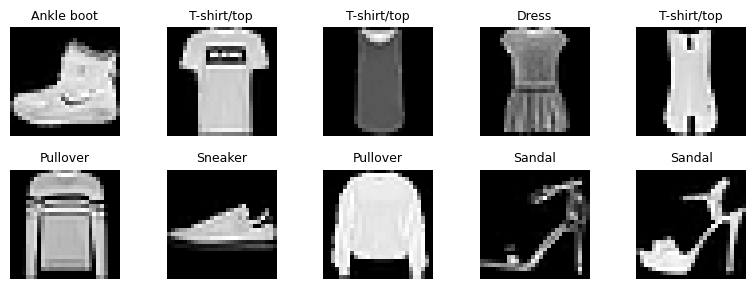

In [4]:
# Quick visual check: show a few images
plt.figure(figsize=(8, 3))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()


## 2) Baseline model (simple neural network)
This is a small Multi-Layer Perceptron (MLP):
- Flatten image into a vector
- 1 hidden layer (ReLU)
- Output layer (Softmax) for 10 classes

> **Note:** We focus on *meaning* and *results*, not heavy math.


In [5]:
def build_mlp(dropout_rate=0.0):
    model = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(10, activation="softmax")
    ])
    return model


In [6]:
# Baseline settings (keep these for the first run)
baseline_lr = 1e-3
baseline_epochs = 10
baseline_dropout = 0.0

baseline_model = build_mlp(dropout_rate=baseline_dropout)

baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=baseline_lr),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Train baseline
history_base = baseline_model.fit(
    x_train, y_train,
    validation_split=0.2,
    epochs=baseline_epochs,
    batch_size=128,
    verbose=1
)


Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8024 - loss: 0.5826 - val_accuracy: 0.8241 - val_loss: 0.4798
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 851us/step - accuracy: 0.8531 - loss: 0.4194 - val_accuracy: 0.8570 - val_loss: 0.4023
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 851us/step - accuracy: 0.8630 - loss: 0.3826 - val_accuracy: 0.8613 - val_loss: 0.3818
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8739 - loss: 0.3522 - val_accuracy: 0.8694 - val_loss: 0.3605
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 940us/step - accuracy: 0.8802 - loss: 0.3338 - val_accuracy: 0.8729 - val_loss: 0.3470
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 878us/step - accuracy: 0.8852 - loss: 0.3170 - val_accuracy: 0.8687 - val_loss: 0.3642
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 888us/step - accuracy: 0.8894 - loss: 0.3023 - val_accuracy: 0.8771 - val_loss: 0.3473
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 925us/step - accuracy: 0.8917 - loss: 0.2935 - val_

In [8]:
# Evaluate on test data
base_test_loss, base_test_acc = baseline_model.evaluate(x_test, y_test, verbose=0)
print(f"Baseline test accuracy: {base_test_acc:.4f}")


Baseline test accuracy: 0.8747


## 3) Plot training vs validation curves
**What to look for**
- If training goes up but validation goes down → overfitting
- If both are low → underfitting (model too simple, or not enough training)
- If curves jump wildly → learning rate may be too high


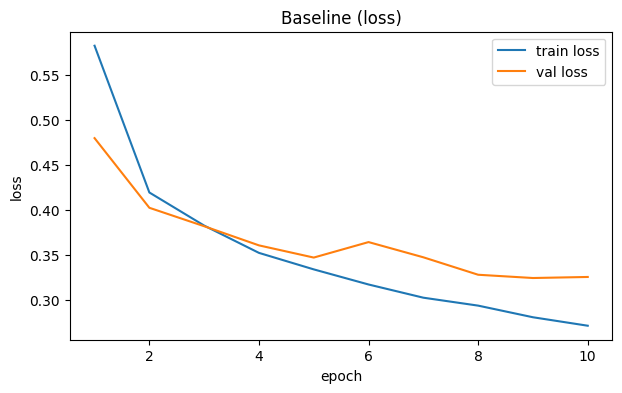

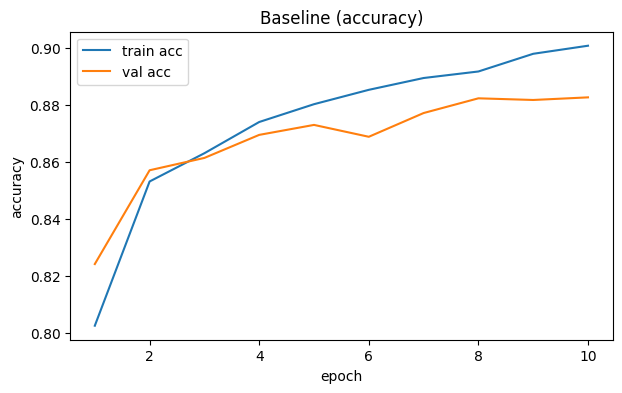

In [9]:
def plot_history(history, title="Training curves"):
    hist = history.history
    epochs = range(1, len(hist["loss"]) + 1)

    plt.figure(figsize=(7,4))
    plt.plot(epochs, hist["loss"], label="train loss")
    plt.plot(epochs, hist["val_loss"], label="val loss")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title(title + " (loss)")
    plt.legend()
    plt.show()

    plt.figure(figsize=(7,4))
    plt.plot(epochs, hist["accuracy"], label="train acc")
    plt.plot(epochs, hist["val_accuracy"], label="val acc")
    plt.xlabel("epoch")
    plt.ylabel("accuracy")
    plt.title(title + " (accuracy)")
    plt.legend()
    plt.show()

plot_history(history_base, title="Baseline")


## 4) Quick error inspection (a few wrong predictions)
This helps you *understand failure modes* (not just a score).


Number of wrong predictions: 1253


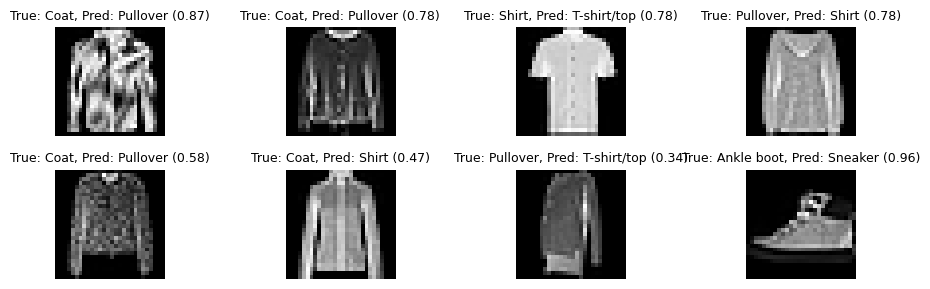

In [14]:
# Predict on test set
probs = baseline_model.predict(x_test, verbose=0)
preds = np.argmax(probs, axis=1)

wrong_idx = np.where(preds != y_test)[0]
print("Number of wrong predictions:", len(wrong_idx))

# Show a few wrong examples
n_show = 8
plt.figure(figsize=(10, 3))
for j, idx in enumerate(wrong_idx[:n_show]):
    plt.subplot(2, 4, j+1)
    plt.imshow(x_test[idx], cmap="gray")
    true_label = class_names[y_test[idx]]
    pred_label = class_names[preds[idx]]
    conf = probs[idx, preds[idx]]
    plt.title(f"True: {true_label}, Pred: {pred_label} ({conf:.2f})", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()


## 5) ONE-change experiment
Choose **ONE** knob to change:
- `learning_rate` (LR)
- `dropout_rate`
- `epochs`

**Rule:** Change only one thing so you can explain what happened.


In [12]:
# ===== Choose your ONE change here =====

experiment_name = "dropout"  # options: "learning_rate", "dropout", "epochs"

# Start from baseline values:
new_lr = baseline_lr
new_dropout = baseline_dropout
new_epochs = baseline_epochs

# Now change ONE thing:
if experiment_name == "learning_rate":
    new_lr = 5e-3        # try: 5e-4, 1e-3, 5e-3
elif experiment_name == "dropout":
    new_dropout = 0.3    # try: 0.2, 0.3, 0.5
elif experiment_name == "epochs":
    new_epochs = 20      # try: 5, 15, 20

print("Experiment:", experiment_name)
print("LR:", new_lr, "Dropout:", new_dropout, "Epochs:", new_epochs)


Experiment: dropout
LR: 0.001 Dropout: 0.3 Epochs: 10


In [15]:
# Build + train the new model
variant_model = build_mlp(dropout_rate=new_dropout)

variant_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=new_lr),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_var = variant_model.fit(
    x_train, y_train,
    validation_split=0.2,
    epochs=new_epochs,
    batch_size=128,
    verbose=1
)

var_test_loss, var_test_acc = variant_model.evaluate(x_test, y_test, verbose=0)
print(f"Variant test accuracy:  {var_test_acc:.4f}")


Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7768 - loss: 0.6491 - val_accuracy: 0.8377 - val_loss: 0.4585
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8394 - loss: 0.4529 - val_accuracy: 0.8556 - val_loss: 0.3980
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 918us/step - accuracy: 0.8523 - loss: 0.4124 - val_accuracy: 0.8638 - val_loss: 0.3816
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 897us/step - accuracy: 0.8631 - loss: 0.3814 - val_accuracy: 0.8681 - val_loss: 0.3618
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 899us/step - accuracy: 0.8689 - loss: 0.3652 - val_accuracy: 0.8742 - val_loss: 0.3498
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 818us/step - accuracy: 0.8724 - loss: 0.3502 - val_accuracy: 0.8766 - val_loss: 0.3475
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 844us/step - accuracy: 0.8758 - loss: 0.3378 - val_accuracy: 0.8783 - val_loss: 0.3378
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 850us/step - accuracy: 0.8800 - loss: 0.3274 - val_

## 6) Compare baseline vs variant (curves + simple table)
**Take 1 screenshot** of the comparison plots (baseline vs variant).


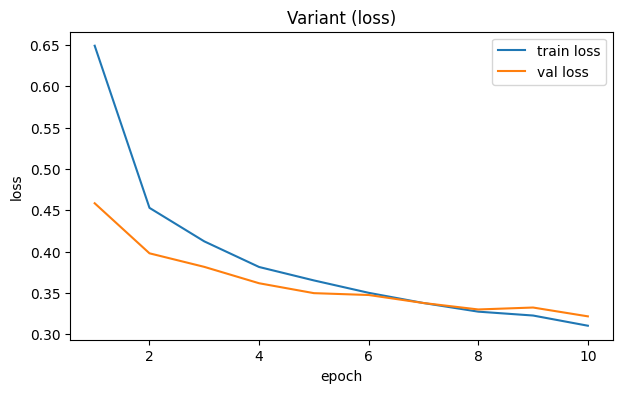

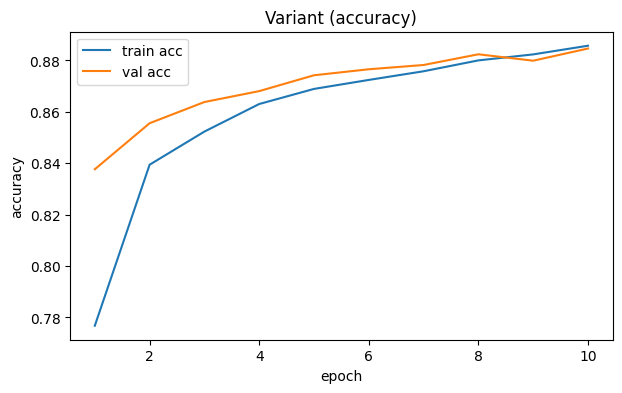

In [16]:
plot_history(history_var, title="Variant")


In [17]:
# Simple comparison table
import pandas as pd

summary = pd.DataFrame([
    {"model":"baseline", "lr":baseline_lr, "dropout":baseline_dropout, "epochs":baseline_epochs, "test_acc":base_test_acc},
    {"model":"variant",  "lr":new_lr,      "dropout":new_dropout,      "epochs":new_epochs,      "test_acc":var_test_acc},
])
summary


,model,lr,dropout,epochs,test_acc
0,baseline,0.001,0.0,10,0.8747
1,variant,0.001,0.3,10,0.8733


## 7) 6-sentence memo (copy/paste and fill)
Write in **plain English** (no math). Keep it short.

1) **Goal:** We wanted to ____ (business or dataset goal).  
2) **Setup:** We used Fashion-MNIST, a simple MLP, and split training/validation with `validation_split=0.2`.  
3) **Result:** Baseline test accuracy was ____, and the variant test accuracy was ____.  
4) **Issue:** The curves suggest ____ (overfitting / underfitting / unstable training / slow learning).  
5) **Fix (ONE change):** We changed ____ (LR/dropout/epochs) to ____ and observed ____.  
6) **Next step:** Next, we would try ____ (early stopping, another LR, more data, CNN next week, etc.).


### Optional (if time): Early stopping (simple safety)
Early stopping stops training when validation stops improving.


Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8030 - loss: 0.5788 - val_accuracy: 0.8434 - val_loss: 0.4567
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 901us/step - accuracy: 0.8546 - loss: 0.4182 - val_accuracy: 0.8590 - val_loss: 0.4079
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 978us/step - accuracy: 0.8685 - loss: 0.3751 - val_accuracy: 0.8693 - val_loss: 0.3729
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 989us/step - accuracy: 0.8747 - loss: 0.3512 - val_accuracy: 0.8680 - val_loss: 0.3666
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 969us/step - accuracy: 0.8810 - loss: 0.3333 - val_accuracy: 0.8729 - val_loss: 0.3625
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 884us/step - accuracy: 0.8865 - loss: 0.3168 - val_accuracy: 0.8760 - val_loss: 0.3459
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 877us/step - accuracy: 0.8923 - loss: 0.2996 - val_accuracy: 0.8798 - val_loss: 0.3378
Epoch 8/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 765us/step - accuracy: 0.8947 - loss: 0.2900 - va

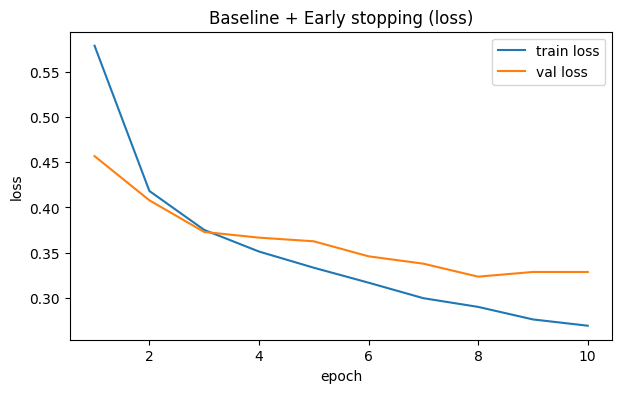

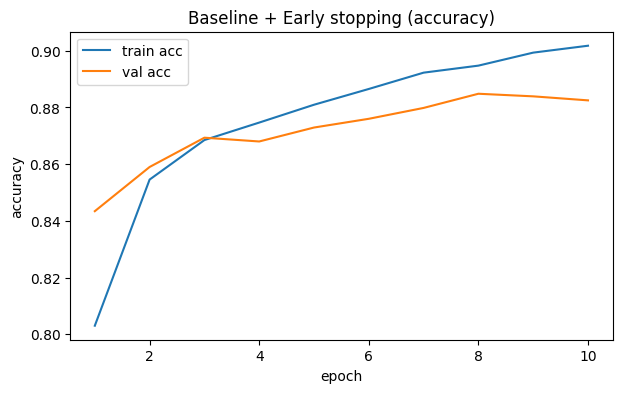

In [18]:
# Uncomment to try early stopping (optional)
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
model_es = build_mlp(dropout_rate=baseline_dropout)
model_es.compile(optimizer=keras.optimizers.Adam(learning_rate=baseline_lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_es = model_es.fit(x_train, y_train, validation_split=0.2, epochs=30, batch_size=128, callbacks=[early_stop], verbose=1)
plot_history(history_es, title="Baseline + Early stopping")
